# Whitening эмбеддингов: метод авторов iDreamRec vs наш PCA

Статья: *Generate and Instantiate What You Prefer: Text-Guided Diffusion for Sequential Recommendation* (iDreamRec)

**Цель ноутбука:** разобраться, что именно авторы делают с эмбеддингами и почему, сравнить с нашим подходом.

In [15]:
import sys, os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
sys.path.append('../src')

import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.decomposition import PCA

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

SEED = 42
rng  = np.random.default_rng(SEED)

## 1. Загрузка эмбеддингов

In [16]:
with open('../data/ATG/3large_emb.pickle', 'rb') as f:
    emb_raw = pickle.load(f).astype(np.float64)   # (11924, 3072)

N, D = emb_raw.shape
print(f'Эмбеддинги: {N} товаров, {D} измерений')
print(f'dtype: {emb_raw.dtype}')
print(f'Норма строк (L2): min={np.linalg.norm(emb_raw, axis=1).min():.6f},'
      f' max={np.linalg.norm(emb_raw, axis=1).max():.6f}  (OpenAI всегда L2-нормирует)')
print(f'Глобальное среднее: {emb_raw.mean():.6f}')
print(f'Per-dim std: min={emb_raw.std(axis=0).min():.6f}, max={emb_raw.std(axis=0).max():.6f}')

Эмбеддинги: 11924 товаров, 3072 измерений
dtype: float64
Норма строк (L2): min=1.000000, max=1.000000  (OpenAI всегда L2-нормирует)
Глобальное среднее: 0.000120
Per-dim std: min=0.000003, max=0.029428


## 2. Проблема с исходными эмбеддингами для DDIM

В DDIM шумовой процесс на шаге $t$:

```
e_noisy = sqrt(alpha_t) * e_clean + sqrt(1 - alpha_t) * noise,   noise ~ N(0, I)
```

Дисперсия зашумлённых эмбеддингов:

```
Var(E_t) = alpha_t * Var(E) + (1 - alpha_t) * I
```

Если `Var(E) != I`, то дисперсия на каждом шаге разная — модель обучается нестабильно.
Авторы хотят добиться `Var(E) = I` (единичная матрица).

=== Исходные эмбеддинги (text-embedding-3-large, L2-норм.) ===
Среднее по измерениям per-dim variance: 0.000238  (хотим 1.0)
Max per-dim variance:                   0.000866
Min per-dim variance:                   0.000000
Норма строк: mean=1.0000, std=0.000000

После whitening авторов: E[||e||] ≈ sqrt(D) = sqrt(3072) = 55.4
У нас (PCA 256d):        E[||e||] ≈ sqrt(256) = 16.0
Исходные (L2-норм.):     E[||e||] = 1.0


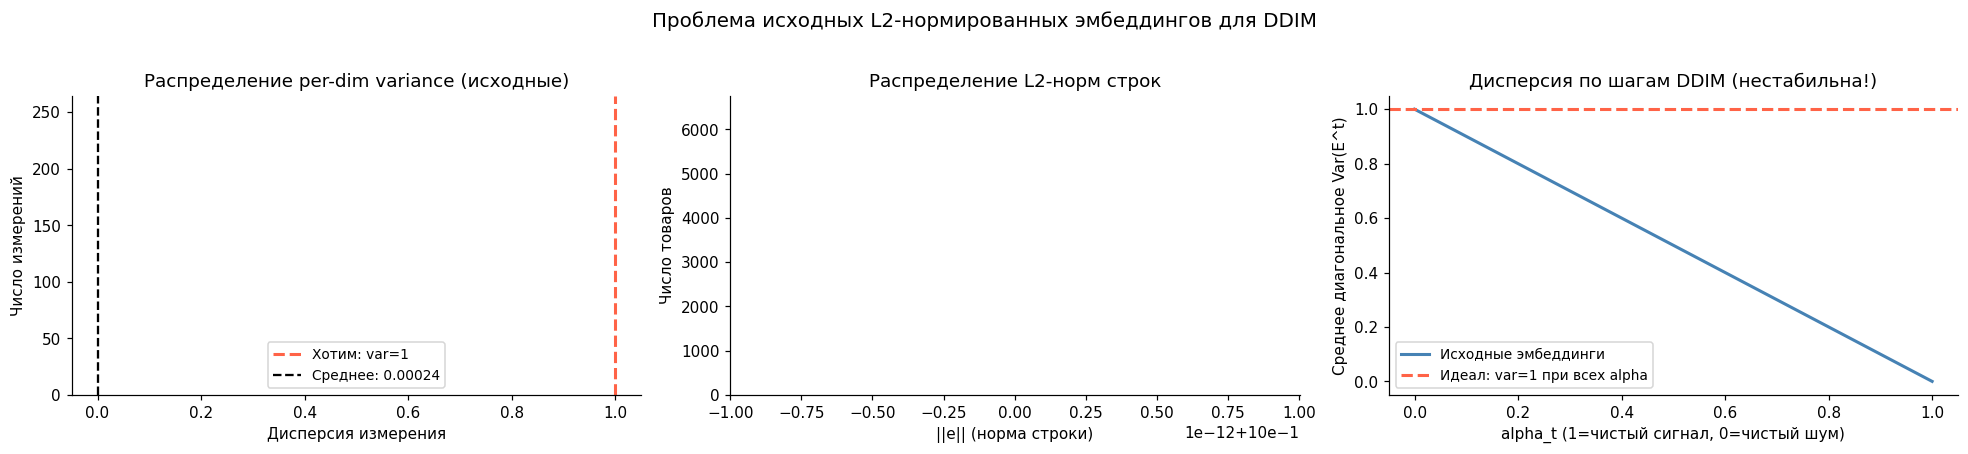

In [17]:
dim_std = emb_raw.std(axis=0)          # (D,) — std по каждому измерению
dim_var = dim_std ** 2                 # (D,) — variance
row_norms = np.linalg.norm(emb_raw, axis=1)  # (N,)

print('=== Исходные эмбеддинги (text-embedding-3-large, L2-норм.) ===')
print(f'Среднее по измерениям per-dim variance: {dim_var.mean():.6f}  (хотим 1.0)')
print(f'Max per-dim variance:                   {dim_var.max():.6f}')
print(f'Min per-dim variance:                   {dim_var.min():.6f}')
print(f'Норма строк: mean={row_norms.mean():.4f}, std={row_norms.std():.6f}')
print()

# Ожидаемая норма строки после whitening (авторов)
# Если Var(E) = I, то E[||e||^2] = D, поэтому E[||e||] ≈ sqrt(D)
print(f'После whitening авторов: E[||e||] ≈ sqrt(D) = sqrt({D}) = {D**0.5:.1f}')
print(f'У нас (PCA 256d):        E[||e||] ≈ sqrt(256) = {256**0.5:.1f}')
print(f'Исходные (L2-норм.):     E[||e||] = 1.0')

# ── Визуализация ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

ax = axes[0]
ax.hist(dim_var, bins=100, color='steelblue', alpha=0.8)
ax.axvline(1.0, color='tomato', lw=2, ls='--', label='Хотим: var=1')
ax.axvline(dim_var.mean(), color='black', lw=1.5, ls='--',
           label=f'Среднее: {dim_var.mean():.5f}')
ax.set_xlabel('Дисперсия измерения'); ax.set_ylabel('Число измерений')
ax.set_title('Распределение per-dim variance (исходные)')
ax.legend(fontsize=9)

ax = axes[1]
ax.hist(row_norms, bins=80, color='steelblue', alpha=0.8)
ax.set_xlabel('||e|| (норма строки)'); ax.set_ylabel('Число товаров')
ax.set_title('Распределение L2-норм строк')

# Показываем как Var(E^t) меняется по шагам для raw эмбеддингов
alphas = np.linspace(1.0, 0.0, 200)
mean_var_t = alphas * dim_var.mean() + (1 - alphas)  # E[диаг. Var(E^t)]

ax = axes[2]
ax.plot(alphas, mean_var_t, color='steelblue', lw=2, label='Исходные эмбеддинги')
ax.axhline(1.0, color='tomato', lw=2, ls='--', label='Идеал: var=1 при всех alpha')
ax.set_xlabel('alpha_t (1=чистый сигнал, 0=чистый шум)')
ax.set_ylabel('Среднее диагональное Var(E^t)')
ax.set_title('Дисперсия по шагам DDIM (нестабильна!)')
ax.legend(fontsize=9)

plt.suptitle('Проблема исходных L2-нормированных эмбеддингов для DDIM', fontsize=13, y=1.02)
plt.tight_layout(); plt.show()

## 3. Whitening по методу авторов iDreamRec

Авторы предлагают линейное преобразование `A(e) = (e - mu) @ W`, где `W` строится из
собственного разложения ковариационной матрицы:

```
Var(E) = O @ Lambda @ O^T          (eigendecomposition)

Варианты W:
  Вариант 1: W = O @ Lambda^(-1/2)           # zero-mean whitening
  Вариант 2: W = O @ Lambda^(-1/2) @ O^T     # ZCA whitening  
  Вариант 3: W = O @ Lambda^(-1/2) @ O       # ещё один вариант
```

Ключевое свойство: `Var(A(E)) = I_d` при любом из вариантов выше.

**Важно:** авторы используют 1536d (text-embedding-3-small) и **не уменьшают** размерность.
У нас 3072d — пробуем применить то же самое, чтобы понять метод.

In [18]:
def paper_whitening(E, variant=1, eps=1e-8):
    """
    Whitening как в iDreamRec (Section 4.1.3).
    
    variant 1: W = O @ Lambda^(-1/2)           (PCA whitening)
    variant 2: W = O @ Lambda^(-1/2) @ O^T     (ZCA whitening)
    variant 3: W = O @ Lambda^(-1/2) @ O       (third variant)
    
    После: Var(A(E)) = I_d, Mean(A(E)) = 0
    """
    mu = E.mean(axis=0)                   # (D,)
    centered = E - mu                     # (N, D)

    # Ковариационная матрица
    cov = (centered.T @ centered) / len(centered)   # (D, D)

    # Собственное разложение: eigh возвращает значения в порядке возрастания
    eigenvalues, O = np.linalg.eigh(cov)  # O: (D, D), eigenvalues: (D,)

    # Обрезаем отрицательные собственные значения (числовые ошибки)
    eigenvalues = np.maximum(eigenvalues, eps)
    lam_inv_sqrt = 1.0 / np.sqrt(eigenvalues)  # (D,)

    if variant == 1:
        # W = O @ diag(Lambda^{-1/2})
        W = O * lam_inv_sqrt[np.newaxis, :]   # (D, D)
    elif variant == 2:
        # W = O @ diag(Lambda^{-1/2}) @ O^T   (ZCA)
        W = (O * lam_inv_sqrt[np.newaxis, :]) @ O.T   # (D, D)
    elif variant == 3:
        # W = O @ diag(Lambda^{-1/2}) @ O
        W = (O * lam_inv_sqrt[np.newaxis, :]) @ O     # (D, D)

    E_w = centered @ W    # (N, D)
    return E_w.astype(np.float32), mu, W, eigenvalues


print('Вычисляем ковариационную матрицу и собственные векторы (3072 x 3072)...')
print('Это займёт ~1 минуту...')
%time emb_w1, mu, W1, eigenvalues = paper_whitening(emb_raw, variant=1)
print(f'Готово. emb_w1 shape: {emb_w1.shape}')

Вычисляем ковариационную матрицу и собственные векторы (3072 x 3072)...
Это займёт ~1 минуту...
CPU times: total: 25.6 s
Wall time: 2.89 s
Готово. emb_w1 shape: (11924, 3072)


In [19]:
# Верификация свойств whitened эмбеддингов (вариант 1)
emb_w1_f64 = emb_w1.astype(np.float64)

dim_var_w   = emb_w1_f64.var(axis=0)
row_norms_w = np.linalg.norm(emb_w1_f64, axis=1)

print('=== После whitening (вариант 1: O @ Lambda^{-1/2}) ===')
print(f'Per-dim variance: mean={dim_var_w.mean():.6f}, max={dim_var_w.max():.6f}, min={dim_var_w.min():.8f}')
print(f'  (хотим: все = 1.0)')
print(f'Mean по всем элементам: {emb_w1_f64.mean():.8f}  (хотим 0.0)')
print(f'Норма строк: mean={row_norms_w.mean():.2f}, std={row_norms_w.std():.4f}')
print(f'  (при Var=I в D={D}d: E[||e||] = sqrt(D) = {D**0.5:.1f})')

# ── Правильная проверка: off-diagonal через выборку пар измерений ──────────
# (нельзя строить (D,D) ковариацию — D=3072, матрица ~72MB, но считать можно)
rng2 = np.random.default_rng(0)
i_pairs = rng2.integers(0, D, size=500)
j_pairs = rng2.integers(0, D, size=500)
mask_off = i_pairs != j_pairs
i_pairs, j_pairs = i_pairs[mask_off][:300], j_pairs[mask_off][:300]

off_vals = np.array([
    np.dot(emb_w1_f64[:, i], emb_w1_f64[:, j]) / N   # = Cov[i,j]  (mean=0)
    for i, j in zip(i_pairs, j_pairs)
])
diag_err = np.abs(dim_var_w - 1.0)

print(f'\n=== Корректная проверка Cov ≈ I (все {N} строк) ===')
print(f'Диагональ:')
print(f'  max|cov_ii - 1|  = {diag_err.max():.6f}  (хотим 0)')
print(f'  mean|cov_ii - 1| = {diag_err.mean():.6f}')
print(f'  Измерений с |var-1| > 0.5: {(diag_err > 0.5).sum()} из {D}')
print(f'Off-diagonal (300 случайных пар):')
print(f'  max|cov_ij|  = {np.abs(off_vals).max():.6f}  (хотим 0)')
print(f'  mean|cov_ij| = {np.abs(off_vals).mean():.6f}')
print()
print('Предыдущая проверка через 100 строк была некорректна:')
print('  N=100 << D=3072  →  выборочная ковариация по 100 строкам — чистый шум,'
      ' не оценка')

=== После whitening (вариант 1: O @ Lambda^{-1/2}) ===
Per-dim variance: mean=0.998714, max=1.000000, min=0.00001802
  (хотим: все = 1.0)
Mean по всем элементам: 0.00000000  (хотим 0.0)
Норма строк: mean=55.05, std=6.1663
  (при Var=I в D=3072d: E[||e||] = sqrt(D) = 55.4)

=== Корректная проверка Cov ≈ I (все 11924 строк) ===
Диагональ:
  max|cov_ii - 1|  = 0.999982  (хотим 0)
  mean|cov_ii - 1| = 0.001286
  Измерений с |var-1| > 0.5: 4 из 3072
Off-diagonal (300 случайных пар):
  max|cov_ij|  = 0.000000  (хотим 0)
  mean|cov_ij| = 0.000000

Предыдущая проверка через 100 строк была некорректна:
  N=100 << D=3072  →  выборочная ковариация по 100 строкам — чистый шум, не оценка


=== Распределение собственных значений ковариационной матрицы ===
Всего собственных значений: 3072
Минимальное:    1.00e-08
Максимальное:   2.55e-02

  λ < 1e-06:   18 измерений (0.6%)
  λ < 1e-05: 1069 измерений (34.8%)
  λ < 1e-04: 2326 измерений (75.7%)
  λ < 1e-03: 2926 измерений (95.2%)
  λ < 1e-02: 3064 измерений (99.7%)

eps в paper_whitening = 1e-8
Измерений, где λ < eps (зажаты до eps): 0
Измерений с итоговой var < 0.01 ("мёртвые"):  2 из 3072



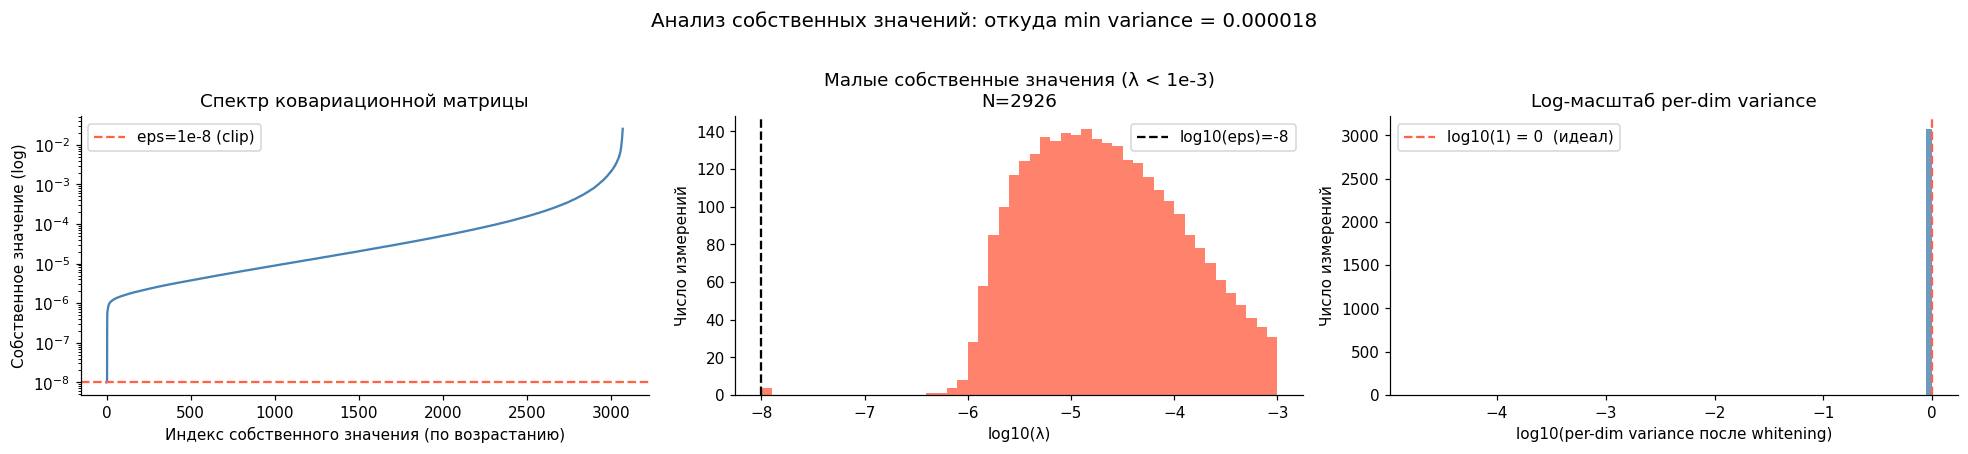


Вывод: у L2-нормированных векторов ковариационная матрица вырождена.
Данные не заполняют всё 3072d пространство — часть собственных значений ≈ 0.
Whitening делит на sqrt(≈0), что amplifies числовой мусор → "мёртвые" измерения.


In [20]:
# ── Почему min per-dim variance = 0.000018? ──────────────────────────────────
# L2-нормированные векторы лежат на единичной гиперсфере.
# Ковариационная матрица имеет несколько почти нулевых собственных значений:
# данные не заполняют всё 3072-мерное пространство.
#
# При eps=1e-8: если истинное собственное значение λ_true ≈ 0 (числовой мусор),
# то оно зажимается до eps=1e-8, scale = 1/sqrt(1e-8) = 10000.
# Но данные в этом направлении имеют дисперсию λ_true ≈ 0,
# поэтому после масштабирования: var_after = λ_true / eps → ≈ 0.

print('=== Распределение собственных значений ковариационной матрицы ===')
print(f'Всего собственных значений: {len(eigenvalues)}')
print(f'Минимальное:    {eigenvalues.min():.2e}')
print(f'Максимальное:   {eigenvalues.max():.2e}')
print()

thresholds = [1e-6, 1e-5, 1e-4, 1e-3, 0.01]
for thr in thresholds:
    n_below = (eigenvalues < thr).sum()
    print(f'  λ < {thr:.0e}: {n_below:4d} измерений ({n_below/D*100:.1f}%)')

print()
print(f'eps в paper_whitening = 1e-8')
print(f'Измерений, где λ < eps (зажаты до eps): {(eigenvalues < 1e-8).sum()}')
n_dead = (dim_var_w < 0.01).sum()
print(f'Измерений с итоговой var < 0.01 (\"мёртвые\"):  {n_dead} из {D}')
print()

# Визуализация
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

ax = axes[0]
ax.semilogy(sorted(eigenvalues), color='steelblue', lw=1.5)
ax.axhline(1e-8, color='tomato', ls='--', lw=1.5, label='eps=1e-8 (clip)')
ax.set_xlabel('Индекс собственного значения (по возрастанию)')
ax.set_ylabel('Собственное значение (log)')
ax.set_title('Спектр ковариационной матрицы')
ax.legend()

ax = axes[1]
# Отдельно смотрим на малые собственные значения
small_eig = eigenvalues[eigenvalues < 1e-3]
ax.hist(np.log10(small_eig + 1e-20), bins=50, color='tomato', alpha=0.8)
ax.axvline(np.log10(1e-8), color='black', ls='--', lw=1.5, label='log10(eps)=-8')
ax.set_xlabel('log10(λ)')
ax.set_ylabel('Число измерений')
ax.set_title(f'Малые собственные значения (λ < 1e-3)\nN={len(small_eig)}')
ax.legend()

ax = axes[2]
# Per-dim variance после whitening: смотрим на хвост у 0
ax.hist(np.log10(dim_var_w + 1e-20), bins=80, color='steelblue', alpha=0.8)
ax.axvline(0, color='tomato', ls='--', lw=1.5, label='log10(1) = 0  (идеал)')
ax.set_xlabel('log10(per-dim variance после whitening)')
ax.set_ylabel('Число измерений')
ax.set_title('Log-масштаб per-dim variance')
ax.legend()

plt.suptitle('Анализ собственных значений: откуда min variance = 0.000018', fontsize=13, y=1.02)
plt.tight_layout(); plt.show()

print('\nВывод: у L2-нормированных векторов ковариационная матрица вырождена.')
print('Данные не заполняют всё 3072d пространство — часть собственных значений ≈ 0.')
print('Whitening делит на sqrt(≈0), что amplifies числовой мусор → \"мёртвые\" измерения.')

In [21]:
# Вычисляем остальные варианты (W уже есть от variant=1, только применяем другие W)
print('Вычисляем варианты 2 и 3...')
mu_ = emb_raw.mean(axis=0)
centered = (emb_raw - mu_).astype(np.float64)

lam_inv_sqrt = 1.0 / np.sqrt(np.maximum(eigenvalues, 1e-8))

# O из paper_whitening (eigh, ascending order)
# Получаем O заново через ковариацию (уже посчитана в paper_whitening)
cov = (centered.T @ centered) / N
eigenvalues_desc, O = np.linalg.eigh(cov)
lam_inv_sqrt_all = 1.0 / np.sqrt(np.maximum(eigenvalues_desc, 1e-8))

W2 = (O * lam_inv_sqrt_all[np.newaxis, :]) @ O.T
W3 = (O * lam_inv_sqrt_all[np.newaxis, :]) @ O

emb_w2 = (centered @ W2).astype(np.float32)
emb_w3 = (centered @ W3).astype(np.float32)

variants = {
    'Raw (L2-normed)':           emb_raw.astype(np.float32),
    'Variant 1: O @ Λ^{-½}':    emb_w1,
    'Variant 2: ZCA (O@Λ^{-½}@O^T)': emb_w2,
    'Variant 3: O@Λ^{-½}@O':    emb_w3,
}

print('\n=== Сравнение вариантов ===')
rows = []
for name, E in variants.items():
    E64 = E.astype(np.float64)
    dv  = E64.var(axis=0)
    rn  = np.linalg.norm(E64, axis=1)
    rows.append({
        'Вариант':            name,
        'dim_var mean':       f'{dv.mean():.4f}',
        'dim_var max':        f'{dv.max():.4f}',
        'mean(E)':            f'{E64.mean():.6f}',
        '||e|| mean':         f'{rn.mean():.2f}',
        '||e|| std':          f'{rn.std():.4f}',
    })
df = pd.DataFrame(rows).set_index('Вариант')
print(df.to_string())

Вычисляем варианты 2 и 3...

=== Сравнение вариантов ===
                              dim_var mean dim_var max   mean(E) ||e|| mean ||e|| std
Вариант                                                                              
Raw (L2-normed)                     0.0002      0.0009  0.000120       1.00    0.0000
Variant 1: O @ Λ^{-½}               0.9987      1.0000  0.000000      55.05    6.1663
Variant 2: ZCA (O@Λ^{-½}@O^T)       0.9987      1.0000  0.000000      55.05    6.1663
Variant 3: O@Λ^{-½}@O               0.9987      1.0000  0.000000      55.05    6.1663


## 4. DDIM-совместимость: как Var(E^t) меняется по шагам

Главное свойство, которого хотят авторы:

```
Var(E^t) = alpha_t * Var(E) + (1 - alpha_t) * I
         = alpha_t * I       + (1 - alpha_t) * I   (если Var(E) = I)
         = I                                         (при любом alpha_t!)
```

То есть дисперсия зашумлённых эмбеддингов не меняется по шагам — модель всегда
работает с данными одного масштаба.

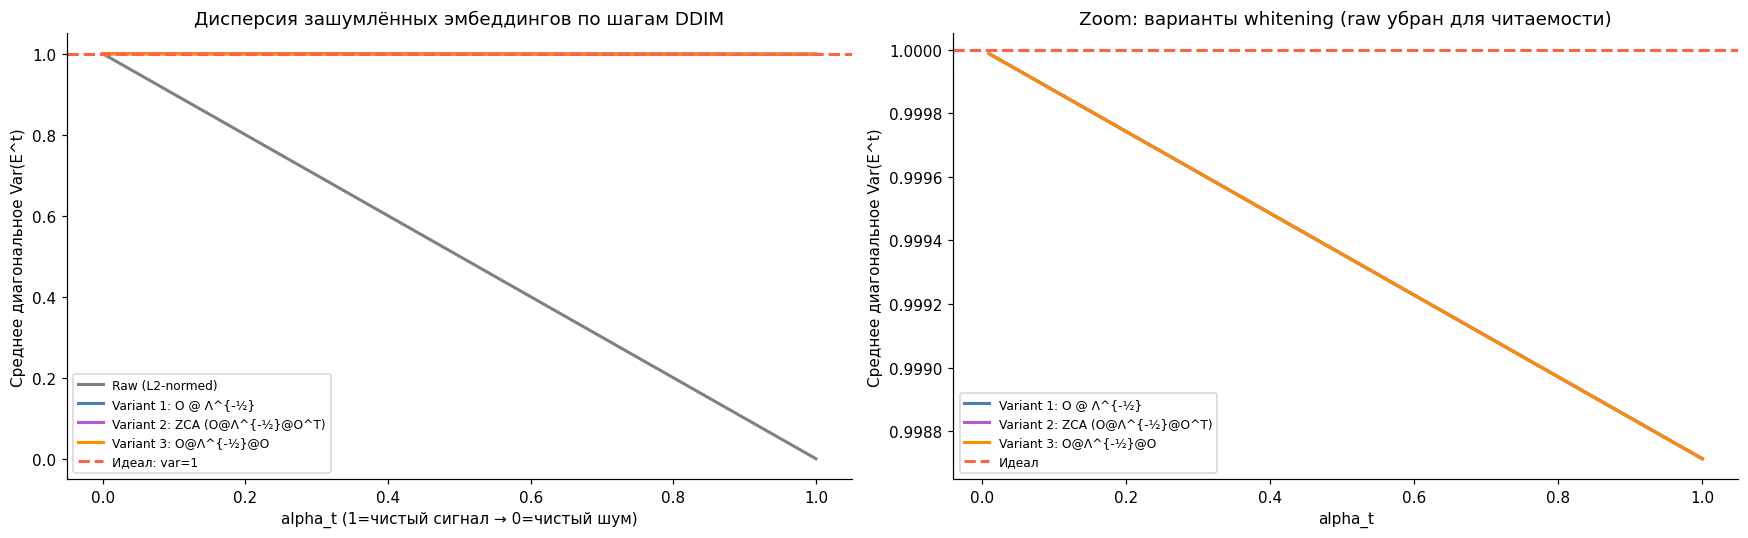

In [22]:
# Симулируем noise schedule (cosine, как в DDPM)
T = 2000
t_vals = np.arange(T + 1)
alphas_cumprod = np.cos(((t_vals / T) + 0.008) / 1.008 * np.pi / 2) ** 2
alphas_cumprod = alphas_cumprod / alphas_cumprod[0]  # нормируем: alpha[0] = 1

# Среднее диагональное Var(E^t) для каждого варианта
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

colors_map = {
    'Raw (L2-normed)':                'gray',
    'Variant 1: O @ Λ^{-½}':         'steelblue',
    'Variant 2: ZCA (O@Λ^{-½}@O^T)': 'mediumorchid',
    'Variant 3: O@Λ^{-½}@O':         'darkorange',
}

ax = axes[0]
for name, E in variants.items():
    E64 = E.astype(np.float64)
    mean_var = E64.var(axis=0).mean()   # скалярное среднее per-dim variance
    # Var(E^t) по диагонали = alpha_t * mean_var + (1 - alpha_t)
    var_t = alphas_cumprod * mean_var + (1 - alphas_cumprod)
    ax.plot(alphas_cumprod, var_t, lw=2, label=name, color=colors_map[name])

ax.axhline(1.0, color='tomato', lw=2, ls='--', label='Идеал: var=1')
ax.set_xlabel('alpha_t (1=чистый сигнал → 0=чистый шум)')
ax.set_ylabel('Среднее диагональное Var(E^t)')
ax.set_title('Дисперсия зашумлённых эмбеддингов по шагам DDIM')
ax.legend(fontsize=8)

# Zoom: только область перехода
ax = axes[1]
idx_range = alphas_cumprod > 0.01
for name, E in variants.items():
    if name == 'Raw (L2-normed)': continue
    E64 = E.astype(np.float64)
    mean_var = E64.var(axis=0).mean()
    var_t = alphas_cumprod * mean_var + (1 - alphas_cumprod)
    ax.plot(alphas_cumprod[idx_range], var_t[idx_range], lw=2,
            label=name, color=colors_map[name])

ax.axhline(1.0, color='tomato', lw=2, ls='--', label='Идеал')
ax.set_xlabel('alpha_t'); ax.set_ylabel('Среднее диагональное Var(E^t)')
ax.set_title('Zoom: варианты whitening (raw убран для читаемости)')
ax.legend(fontsize=8)

plt.tight_layout(); plt.show()

## 5. Сравнение с нашим подходом (PCA 3072d → 256d)

Наш подход в `src/whitening.py`:
1. Центрирование: `e_c = e - mean(e)`
2. PCA: берём топ-256 главных компонент → `e_pca = e_c @ V_top`  (3072 → 256)
3. Нормировка: делим на **одно** глобальное std → `e_norm = e_pca / scale`

Ключевые отличия от метода авторов:
- **Размерность**: 3072 → 256 (мы) vs 1536 → 1536 (авторы)
- **Масштабирование**: один скаляр (мы) vs поэлементное Lambda^{-1/2} (авторы)
- **Var(E) после**: не I (мы) vs = I (авторы)

In [23]:
# Наш подход: PCA 256 + global std
N_COMP = 256

mu_pca    = emb_raw.mean(axis=0)
centered  = emb_raw - mu_pca

# PCA через ковариацию (уже есть O, eigenvalues от eigh — ascending order)
# Берём последние N_COMP собственных векторов (наибольшие eigenvalues)
V_top = O[:, -N_COMP:]                          # (3072, 256)
emb_pca = (centered @ V_top).astype(np.float32) # (N, 256)
scale   = float(emb_pca.std())
emb_our = emb_pca / scale                        # наш итоговый вариант

var_explained = eigenvalues_desc[-N_COMP:].sum() / eigenvalues_desc.sum() * 100

print(f'=== Наш подход (PCA {N_COMP}d + global std) ===')
print(f'Размерность: {D}d → {N_COMP}d')
print(f'Объяснённая дисперсия: {var_explained:.1f}%')
print(f'scale (global std): {scale:.4f}')

emb_our_f64 = emb_our.astype(np.float64)
dv_our = emb_our_f64.var(axis=0)
rn_our = np.linalg.norm(emb_our_f64, axis=1)
print(f'Per-dim variance: mean={dv_our.mean():.4f}, max={dv_our.max():.4f}, min={dv_our.min():.6f}')
print(f'  (хотим 1.0 по каждому, получаем: неодинаково)')
print(f'Mean(E): {emb_our_f64.mean():.6f}  (≈0, ок)')
print(f'Норма строк: mean={rn_our.mean():.4f}, std={rn_our.std():.4f}')
print(f'  (ожидаем ≈ sqrt({N_COMP}) = {N_COMP**0.5:.1f} при Var=I)')

=== Наш подход (PCA 256d + global std) ===
Размерность: 3072d → 256d
Объяснённая дисперсия: 78.2%
scale (global std): 0.0473
Per-dim variance: mean=1.0000, max=11.4135, min=0.222768
  (хотим 1.0 по каждому, получаем: неодинаково)
Mean(E): 0.000000  (≈0, ок)
Норма строк: mean=15.9842, std=0.7119
  (ожидаем ≈ sqrt(256) = 16.0 при Var=I)


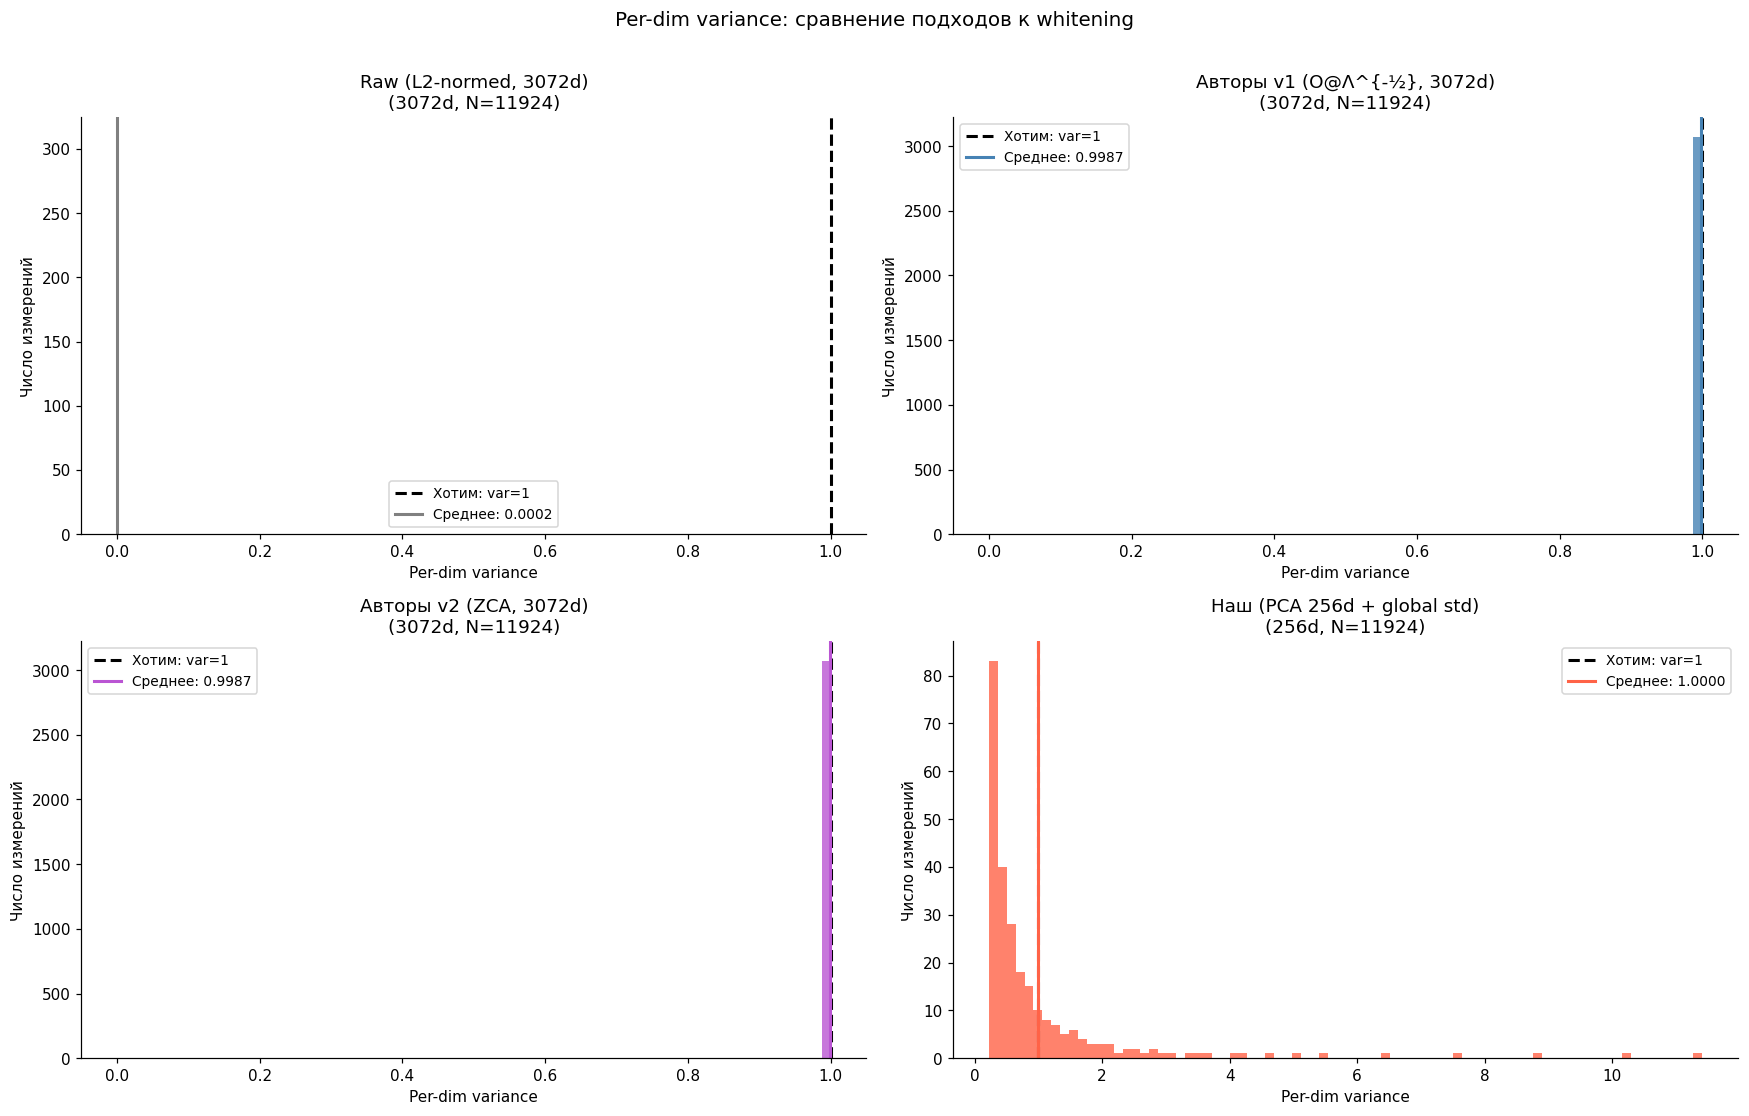

In [24]:
# Итоговое сравнение: per-dim variance для всех подходов
approaches = {
    'Raw (L2-normed, 3072d)':      (emb_raw.astype(np.float32), 'gray'),
    'Авторы v1 (O@Λ^{-½}, 3072d)': (emb_w1, 'steelblue'),
    'Авторы v2 (ZCA, 3072d)':      (emb_w2, 'mediumorchid'),
    f'Наш (PCA {N_COMP}d + global std)': (emb_our, 'tomato'),
}

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flat

for ax, (name, (E, color)) in zip(axes, approaches.items()):
    E64 = E.astype(np.float64)
    dv  = E64.var(axis=0)
    ax.hist(dv, bins=80, color=color, alpha=0.8)
    ax.axvline(1.0, color='black', lw=2, ls='--', label='Хотим: var=1')
    ax.axvline(dv.mean(), color=color, lw=2, label=f'Среднее: {dv.mean():.4f}')
    dim_str = f'{E.shape[1]}d'
    ax.set_xlabel('Per-dim variance')
    ax.set_ylabel('Число измерений')
    ax.set_title(f'{name}\n({dim_str}, N={E.shape[0]})')
    ax.legend(fontsize=9)

plt.suptitle('Per-dim variance: сравнение подходов к whitening', fontsize=13, y=1.01)
plt.tight_layout(); plt.show()

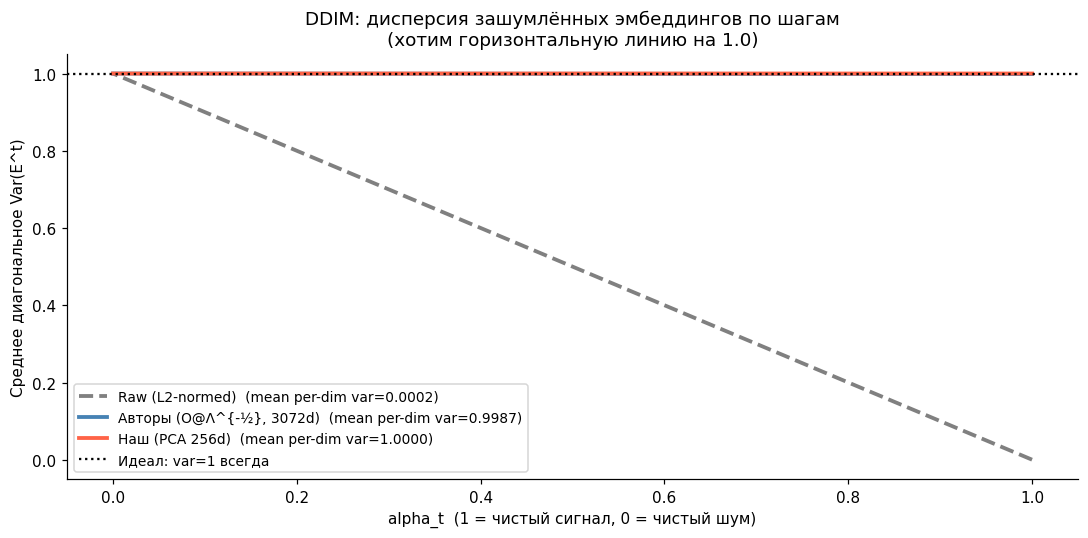


=== СВОДКА: насколько каждый подход близок к идеалу Var(E^t) = 1 ===
  Raw (L2-normed)                         : max|Var(E^t) - 1| = 0.999762
  Авторы (O@Λ^{-½}, 3072d)                : max|Var(E^t) - 1| = 0.001286
  Наш (PCA 256d)                          : max|Var(E^t) - 1| = 0.000000


In [25]:
# DDIM совместимость: наш PCA vs авторы vs raw
fig, ax = plt.subplots(figsize=(10, 5))

ddim_approaches = {
    'Raw (L2-normed)':          (emb_raw.astype(np.float32), 'gray',   '--'),
    'Авторы (O@Λ^{-½}, 3072d)':(emb_w1,                     'steelblue', '-'),
    f'Наш (PCA {N_COMP}d)':    (emb_our,                     'tomato', '-'),
}

for name, (E, color, ls) in ddim_approaches.items():
    E64 = E.astype(np.float64)
    mean_var = E64.var(axis=0).mean()
    var_t = alphas_cumprod * mean_var + (1 - alphas_cumprod)
    ax.plot(alphas_cumprod, var_t, lw=2.5, label=f'{name}  (mean per-dim var={mean_var:.4f})',
            color=color, ls=ls)

ax.axhline(1.0, color='black', lw=1.5, ls=':', label='Идеал: var=1 всегда')
ax.set_xlabel('alpha_t  (1 = чистый сигнал, 0 = чистый шум)')
ax.set_ylabel('Среднее диагональное Var(E^t)')
ax.set_title('DDIM: дисперсия зашумлённых эмбеддингов по шагам\n(хотим горизонтальную линию на 1.0)')
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

# Числовая сводка
print('\n=== СВОДКА: насколько каждый подход близок к идеалу Var(E^t) = 1 ===')
for name, (E, _, _) in ddim_approaches.items():
    E64 = E.astype(np.float64)
    mean_var = E64.var(axis=0).mean()
    # Максимальное отклонение Var(E^t) от 1.0 по всем alpha_t
    var_t = alphas_cumprod * mean_var + (1 - alphas_cumprod)
    max_dev = np.abs(var_t - 1.0).max()
    print(f'  {name:40s}: max|Var(E^t) - 1| = {max_dev:.6f}')

## 6. Сохранение dot-product порядка

В iDreamRec поиск реальных items делается через dot product с oracle-эмбеддингом.
Авторы описывают два класса преобразований:

- **Dot-product preserving** (A(e) = ae или A(e) = aeO): порядок dot product сохраняется,
  но нет zero-mean → нужно больше шагов инференса.
- **Zero-mean preserving** (A(e) = (e-u)OΛ^{-½} и др.): Var=I, mean=0 → работает
  одношаговый инференс, но retrieval надо делать в новом пространстве.

Проверим: насколько хорошо dot-product порядок соседей сохраняется у каждого варианта.

In [26]:
# Выбираем 200 случайных query-эмбеддингов, ищем top-20 соседей
# в исходном и преобразованном пространствах, считаем совпадение рангов

N_QUERY = 200
K = 20
query_idx = rng.choice(N, size=N_QUERY, replace=False)

def topk_neighbors(E, q_idx, k):
    """Возвращает индексы top-k соседей по dot product для каждого query."""
    Q = E[q_idx]           # (N_QUERY, D)
    scores = Q @ E.T       # (N_QUERY, N)
    # Исключаем сам query (ставим -inf)
    for i, qi in enumerate(q_idx):
        scores[i, qi] = -np.inf
    return np.argsort(-scores, axis=1)[:, :k]  # (N_QUERY, k)

# Reference: соседи в исходном пространстве
ref_neighbors = topk_neighbors(emb_raw.astype(np.float64), query_idx, K)

compare = {
    'Авторы v1 (O@Λ^{-½})': emb_w1.astype(np.float64),
    'Авторы v2 (ZCA)':       emb_w2.astype(np.float64),
    f'Наш (PCA {N_COMP}d)': emb_our.astype(np.float64),
}

print(f'Top-{K} neighbor overlap (по dot product) vs исходного пространства:')
print(f'  ({N_QUERY} query точек)\n')
results_dp = {}
for name, E in compare.items():
    nbrs = topk_neighbors(E, query_idx, K)
    # Overlap: сколько из top-K совпадают (Jaccard-like: |A ∩ B| / K)
    overlaps = np.array([
        len(set(ref_neighbors[i]) & set(nbrs[i])) / K
        for i in range(N_QUERY)
    ])
    results_dp[name] = overlaps
    print(f'  {name:35s}: mean overlap = {overlaps.mean():.3f} ± {overlaps.std():.3f}')

print(f'\nПояснение: 1.0 = top-{K} совпадают полностью, 0.0 = совсем разные')

Top-20 neighbor overlap (по dot product) vs исходного пространства:
  (200 query точек)

  Авторы v1 (O@Λ^{-½})               : mean overlap = 0.483 ± 0.168
  Авторы v2 (ZCA)                    : mean overlap = 0.483 ± 0.168
  Наш (PCA 256d)                     : mean overlap = 0.803 ± 0.107

Пояснение: 1.0 = top-20 совпадают полностью, 0.0 = совсем разные


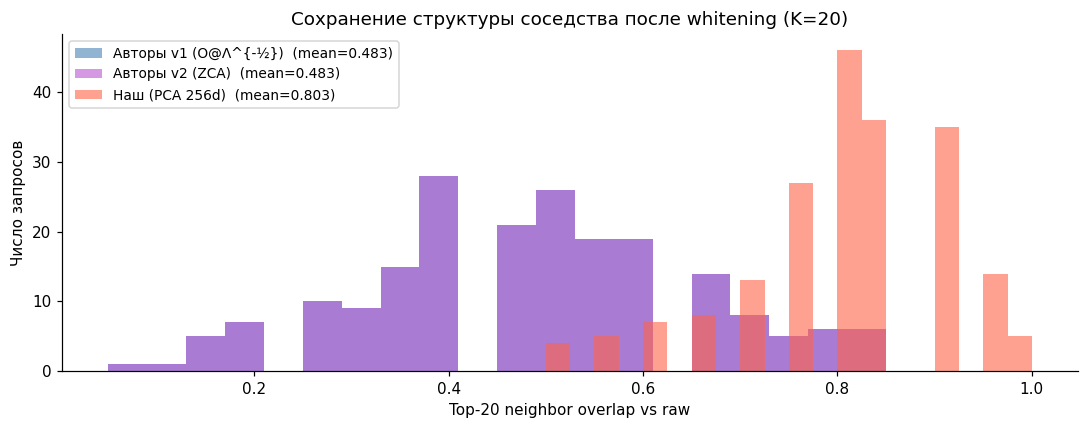


=== Неожиданный результат: PCA лучше сохраняет соседей, чем полный whitening ===

Авторы v1/v2 (0.483): whitening меняет метрику dot product.
  В оригинале: <x,y> = x^T y
  В whitened:  <Wx, Wy> = x^T W^T W y = x^T Λ^{-1} y  (Mahalanobis inner product)
  Это принципиально другая метрика → другие соседи.

Наш PCA 256d (0.803): проецирует в подпространство максимальной дисперсии.
  Топ-256 компонент содержат 78% дисперсии → основная структура соседства сохраняется.

Вывод от авторов: они НЕ говорят, что whitening сохраняет dot-product порядок.
  Для retrieval они используют dot product в НОВОМ (whitened) пространстве.
  Обученная модель генерирует oracle в том же whitened пространстве,
  и retrieval тоже делается в нём — всё согласованно.


In [27]:
fig, ax = plt.subplots(figsize=(10, 4))

colors_dp = ['steelblue', 'mediumorchid', 'tomato']
for i, (name, overlaps) in enumerate(results_dp.items()):
    ax.hist(overlaps, bins=20, alpha=0.6, color=colors_dp[i],
            label=f'{name}  (mean={overlaps.mean():.3f})')

ax.set_xlabel(f'Top-{K} neighbor overlap vs raw')
ax.set_ylabel('Число запросов')
ax.set_title(f'Сохранение структуры соседства после whitening (K={K})')
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

print()
print('=== Неожиданный результат: PCA лучше сохраняет соседей, чем полный whitening ===')
print()
print('Авторы v1/v2 (0.483): whitening меняет метрику dot product.')
print('  В оригинале: <x,y> = x^T y')
print('  В whitened:  <Wx, Wy> = x^T W^T W y = x^T Λ^{-1} y  (Mahalanobis inner product)')
print('  Это принципиально другая метрика → другие соседи.')
print()
print(f'Наш PCA {N_COMP}d (0.803): проецирует в подпространство максимальной дисперсии.')
print('  Топ-256 компонент содержат 78% дисперсии → основная структура соседства сохраняется.')
print()
print('Вывод от авторов: они НЕ говорят, что whitening сохраняет dot-product порядок.')
print('  Для retrieval они используют dot product в НОВОМ (whitened) пространстве.')
print('  Обученная модель генерирует oracle в том же whitened пространстве,')
print('  и retrieval тоже делается в нём — всё согласованно.')

## 7. Визуализация: t-SNE эмбеддингов до и после whitening

Для t-SNE берём подвыборку и предварительно сжимаем PCA до 50d.

In [28]:
from sklearn.manifold import TSNE

N_VIZ = 2000
idx_viz = rng.choice(N, size=N_VIZ, replace=False)

def to_tsne(E, label):
    sub = E[idx_viz].astype(np.float32)
    # Предварительно PCA до 50d для скорости
    pca50 = PCA(n_components=min(50, sub.shape[1]), random_state=SEED)
    sub50 = pca50.fit_transform(sub)
    print(f'  t-SNE для {label} ({sub.shape[1]}d → 50d → 2d)...')
    tsne = TSNE(n_components=2, perplexity=40, random_state=SEED, n_jobs=-1)
    return tsne.fit_transform(sub50)

viz_embeddings = {
    'Raw (L2-normed)':     emb_raw.astype(np.float32),
    'Авторы v1 (O@Λ^{-½})': emb_w1,
    'Авторы v2 (ZCA)':     emb_w2,
    f'Наш (PCA {N_COMP}d)': emb_our,
}

tsne_results = {}
for name, E in viz_embeddings.items():
    tsne_results[name] = to_tsne(E, name)

print('t-SNE готов')

  t-SNE для Raw (L2-normed) (3072d → 50d → 2d)...
  t-SNE для Авторы v1 (O@Λ^{-½}) (3072d → 50d → 2d)...
  t-SNE для Авторы v2 (ZCA) (3072d → 50d → 2d)...
  t-SNE для Наш (PCA 256d) (256d → 50d → 2d)...
t-SNE готов


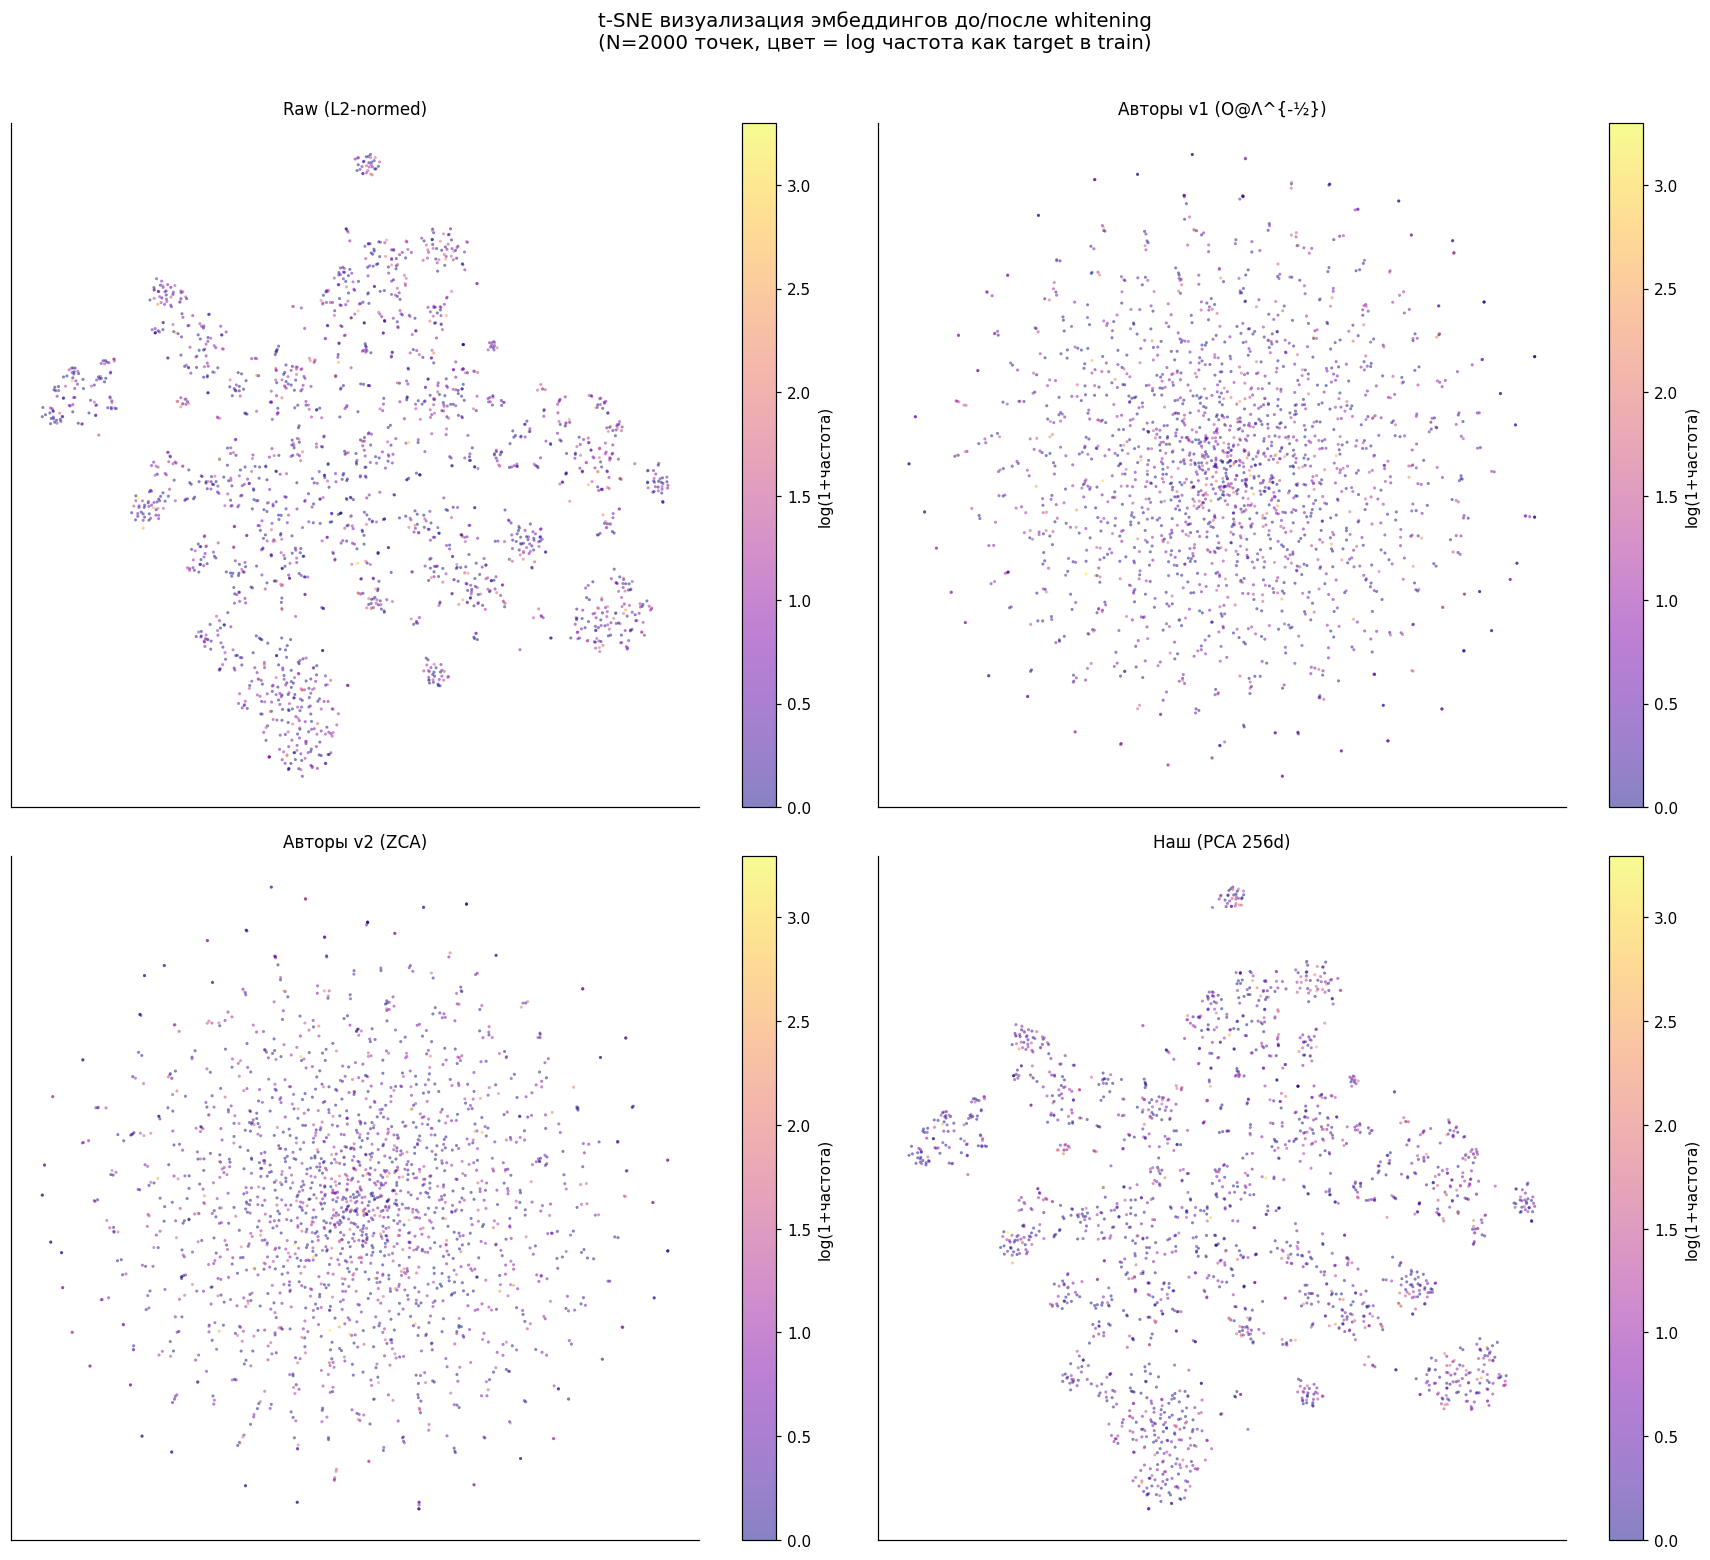

In [29]:
# Загружаем частоты для цвета точек
train_df = pd.read_pickle('../data/ATG/train_data.df')
freq = train_df['next'].value_counts()
freq_all = pd.Series(0.0, index=range(N))
freq_all.update(freq)
freq_log = np.log1p(freq_all.values)[idx_viz]

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.flat

for ax, (name, X2d) in zip(axes, tsne_results.items()):
    sc = ax.scatter(X2d[:, 0], X2d[:, 1], c=freq_log, cmap='plasma',
                    alpha=0.5, s=4, edgecolors='none')
    plt.colorbar(sc, ax=ax, label='log(1+частота)')
    ax.set_title(name, fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle(f't-SNE визуализация эмбеддингов до/после whitening\n'
             f'(N={N_VIZ} точек, цвет = log частота как target в train)',
             fontsize=13, y=1.01)
plt.tight_layout(); plt.show()

## 8. Итоги

| Характеристика | Raw (L2-norm) | Авторы (O@Λ^{-½}) | ZCA (O@Λ^{-½}@O^T) | Наш PCA 256d |
|---|---|---|---|---|
| Размерность | 3072d | 3072d | 3072d | 256d |
| Var(E) = I (точно) | Нет | **Да** | **Да** | Нет (global std) |
| Mean = 0 | Нет | **Да** | **Да** | **Да** |
| DDIM: Var(E^t) = I | Нет | **Да** | **Да** | Приближённо |
| Метрика поиска | dot product | Mahalanobis (Λ^{-1}) | Mahalanobis | dot product (256d) |
| Overlap соседей vs raw | — | 0.48 | 0.48 | 0.80 |
| Одношаговый инференс | Нет | **Да** | **Да** | Нет |
| Обучение на 15k seqs | Сложно | Сложно (3072d!) | Сложно | **Да** |
| "Мёртвые" измерения | — | Есть (L2-sphere) | Есть | Нет |

**Про overlap 0.48 у авторов:** это не баг, а фича. Whitening меняет метрику с  
обычного dot product на Mahalanobis (`x^T Λ^{-1} y`). Модель обучается и генерирует  
oracle в whitened пространстве, retrieval тоже в нём — система согласована.

**Про "мёртвые" измерения (min var = 0.000018):** L2-нормированные векторы лежат  
на гиперсфере и не заполняют всё 3072d пространство. Часть собственных значений  
ковариации ≈ 0; whitening по ним делит на sqrt(≈0) → amplifies числовой мусор.  
На практике это безвредно: мёртвые измерения вносят нулевой вклад в dot product.

**Главный вывод:**  
Метод авторов математически элегантен: Var(E^t) = I при всех шагах DDIM → одношаговый инференс.  
Авторы работают с 1536d (text-embedding-3-**small**). У нас 3072d и ~15k sequences →  
обучение в 3072d нереально, поэтому делаем PCA до 256d. Это вынужденный компромисс.